# HOVER EDA for Selected Worlds

Minimal sanity-check notebook for:
- `W0_baseline`
- `W_U_dominant`

Checks:
- shape / dtypes / missing values
- override rate
- summary statistics
- leakage sanity
- quick distribution plots
- world comparison table


In [14]:
import os 
%ls

 Volume in drive C has no label.
 Volume Serial Number is 0ED3-76A9

 Directory of c:\Users\Lenovo\override_sim\override_sim\hover\Analysis

25/04/2026  22:08    <DIR>          .
25/04/2026  22:28    <DIR>          ..
27/04/2026  19:17             7,847 EDA.ipynb
               1 File(s)          7,847 bytes
               2 Dir(s)  18,180,730,880 bytes free


In [31]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path('../data')
WORLD_FILES = {
    'W0_baseline': DATA_DIR / 'W0_baseline.csv',
    'W_U_dominant': DATA_DIR / 'W_U_dominant.csv',
    'W_B_dominant': DATA_DIR / 'W_B_dominant.csv',
}

KEY_COLS = [
    'stake',
    'time_pressure',
    'policy_strict',
    'audit',
    'ai_prob',
    'purpose_align',
    'override',
]


In [32]:
datasets = {}
for name, path in WORLD_FILES.items():
    if not path.exists():
        raise FileNotFoundError(f'Missing file: {path}')
    datasets[name] = pd.read_csv(path)

list(datasets.keys())


['W0_baseline', 'W_U_dominant', 'W_B_dominant']

In [33]:
for name, df in datasets.items():
    print('=' * 80)
    print(name)
    print('=' * 80)
    print('shape:', df.shape)
    print('\ndtypes:')
    print(df.dtypes.to_string())
    print('\nmissing values:')
    print(df.isna().sum().to_string())
    if 'override' in df.columns:
        print(f'\noverride rate: {df["override"].mean():.4f}')
    print('\nhead:')
    print(df.head().to_string())
    print()


W0_baseline
shape: (50000, 16)

dtypes:
t                     int64
user_id               int64
stake               float64
time_pressure       float64
policy_strict       float64
audit               float64
ai_prob             float64
ai_rec                int64
xai_present           int64
xai_timing            int64
xai_detail          float64
xai_specificity     float64
xai_consistency     float64
xai_faithfulness    float64
purpose_align       float64
override              int64

missing values:
t                   0
user_id             0
stake               0
time_pressure       0
policy_strict       0
audit               0
ai_prob             0
ai_rec              0
xai_present         0
xai_timing          0
xai_detail          0
xai_specificity     0
xai_consistency     0
xai_faithfulness    0
purpose_align       0
override            0

override rate: 0.2500

head:
   t  user_id     stake  time_pressure  policy_strict  audit   ai_prob  ai_rec  xai_present  xai_timing  xai_deta

In [34]:
for name, df in datasets.items():
    cols = [c for c in KEY_COLS if c in df.columns]
    print('=' * 80)
    print(f'Summary stats: {name}')
    print('=' * 80)
    display(df[cols].describe().round(4))


Summary stats: W0_baseline


,stake,time_pressure,policy_strict,audit,ai_prob,purpose_align,override
count,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.000
mean,0.5002,0.4991,0.5001,0.3018,0.3616,0.5188,0.250
std,0.2239,0.2236,0.2244,0.4590,0.3389,0.2645,0.433
min,0.0060,0.0022,0.0028,0.0000,0.0022,0.0000,0.000
25%,0.3264,0.3253,0.3251,0.0000,0.0857,0.2646,0.000
50%,0.4999,0.4999,0.4996,0.0000,0.1944,0.5350,0.000
75%,0.6748,0.6729,0.6744,1.0000,0.7369,0.7546,0.250
max,0.9988,0.9970,0.9979,1.0000,0.9979,1.0000,1.000


Summary stats: W_U_dominant


,stake,time_pressure,policy_strict,audit,ai_prob,purpose_align,override
count,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000
mean,0.5002,0.4991,0.5001,0.3018,0.3616,0.5123,0.2493
std,0.2239,0.2236,0.2244,0.4590,0.3389,0.2640,0.4326
min,0.0060,0.0022,0.0028,0.0000,0.0022,0.0000,0.0000
25%,0.3264,0.3253,0.3251,0.0000,0.0857,0.2585,0.0000
50%,0.4999,0.4999,0.4996,0.0000,0.1944,0.5266,0.0000
75%,0.6748,0.6729,0.6744,1.0000,0.7369,0.7473,0.0000
max,0.9988,0.9970,0.9979,1.0000,0.9979,1.0000,1.0000


Summary stats: W_B_dominant


,stake,time_pressure,policy_strict,audit,ai_prob,purpose_align,override
count,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000,50000.0000
mean,0.5002,0.4991,0.5001,0.3018,0.3616,0.5324,0.2492
std,0.2239,0.2236,0.2244,0.4590,0.3389,0.2648,0.4325
min,0.0060,0.0022,0.0028,0.0000,0.0022,0.0000,0.0000
25%,0.3264,0.3253,0.3251,0.0000,0.0857,0.2764,0.0000
50%,0.4999,0.4999,0.4996,0.0000,0.1944,0.5473,0.0000
75%,0.6748,0.6729,0.6744,1.0000,0.7369,0.7711,0.0000
max,0.9988,0.9970,0.9979,1.0000,0.9979,1.0000,1.0000


We observe that the generated distributions follow the assumptions set at the beginning of the simulator successfully. The main contextual variables behave as expected, and the calibrated target variable remains aligned with the intended override rate.

At the same time, one important observation appears during this first inspection: the two selected datasets look very similar even though they come from different worlds. This leads to the next step of the analysis:

testing the cross-world distributional variance to determine whether the two worlds are actually different at the raw observable level.

In [21]:
import pandas as pd
import numpy as np

def compare_quantiles(df_a: pd.DataFrame, df_b: pd.DataFrame, cols, 
                      quantiles=(0.10, 0.25, 0.50, 0.75, 0.90)) -> pd.DataFrame:
    rows = []

    for col in cols:
        if col not in df_a.columns or col not in df_b.columns:
            continue

        qa = df_a[col].quantile(quantiles)
        qb = df_b[col].quantile(quantiles)

        row = {"column": col}
        diffs = []

        for q in quantiles:
            va = float(qa.loc[q])
            vb = float(qb.loc[q])
            diff = vb - va
            abs_diff = abs(diff)

            row[f"q{int(q*100)}_A"] = va
            row[f"q{int(q*100)}_B"] = vb
            row[f"q{int(q*100)}_diff"] = diff
            row[f"q{int(q*100)}_absdiff"] = abs_diff
            diffs.append(abs_diff)

        row["mean_abs_quantile_diff"] = float(np.mean(diffs))
        row["max_abs_quantile_diff"] = float(np.max(diffs))
        rows.append(row)

    out = pd.DataFrame(rows).sort_values("mean_abs_quantile_diff", ascending=False)
    return out

In [26]:
cols = [
    "stake",
    "time_pressure",
    "policy_strict",
    "audit",
    "ai_prob",
    "purpose_align",
    "override",
]

qdiff = compare_quantiles(datasets['W0_baseline'], datasets['W_U_dominant'], cols)
print(qdiff.round(4).to_string(index=False))

       column  q10_A  q10_B  q10_diff  q10_absdiff  q25_A  q25_B  q25_diff  q25_absdiff  q50_A  q50_B  q50_diff  q50_absdiff  q75_A  q75_B  q75_diff  q75_absdiff  q90_A  q90_B  q90_diff  q90_absdiff  mean_abs_quantile_diff  max_abs_quantile_diff
     override 0.0000 0.0000     0.000        0.000 0.0000 0.0000    0.0000       0.0000 0.0000 0.0000    0.0000       0.0000 0.2500 0.0000   -0.2500       0.2500 1.0000 1.0000     0.000        0.000                  0.0500                 0.2500
purpose_align 0.1480 0.1420    -0.006        0.006 0.2646 0.2585   -0.0061       0.0061 0.5350 0.5266   -0.0084       0.0084 0.7546 0.7473   -0.0073       0.0073 0.8683 0.8623    -0.006        0.006                  0.0068                 0.0084
        stake 0.1965 0.1965     0.000        0.000 0.3264 0.3264    0.0000       0.0000 0.4999 0.4999    0.0000       0.0000 0.6748 0.6748    0.0000       0.0000 0.8034 0.8034     0.000        0.000                  0.0000                 0.0000
policy_strict 0.

We can conclude that the two distributions are strikingly similar at the raw observable level. However, this result is consistent with the current methodological design of the framework.

The current worlds are not primarily designed to represent different operational environments. Instead, they are designed to keep the same or nearly the same logged case structure while varying the behavioral regime behind the decision process. In other words, the log inputs are approximately frozen, while the decision-maker context changes.

This means that the worlds are best interpreted as:

the same or highly similar operational cases,
exposed to different human-AI decision regimes,
leading to different override behaviors.

So the present experiment is mainly isolating decision-maker specificities rather than input-distribution variability. More precisely, what changes across worlds is not only trust, but a combination of:

trust dynamics,
utility sensitivity,
incentive sensitivity,
response to explanations,
perceived purpose alignment.

This interpretation is also coherent with the validation logic of the knowledge-based synthesis phase: the framework currently tests whether changes in behavioral assumptions produce different override responses under a controlled case distribution.

A practical way to state this is:

the current setup freezes the log inputs in order to isolate the effect of human behavioral variation on human-in-the-loop systems.

This is useful because it makes the signal cleaner: differences in override can be attributed more directly to the decision regime, rather than to a different mix of operational cases.

At a later stage, the framework can be extended by varying the logs themselves as well. That would allow testing whether the same behavioral mechanisms remain stable under different input distributions, and whether behavioral signals interact with the case distribution.

There are also limitations to consider:

The worlds are currently under-differentiated at the observable-distribution level, so they should not yet be interpreted as strongly different operational environments.
The current comparison isolates behavioral-regime effects more than environmental effects, which is useful for controlled analysis but narrower than full real-world variation.
Because the logs are approximately fixed across worlds, cross-world differences mainly reflect differences in the decision mechanism rather than broad distribution shift.
This means the present framework is strong for studying human behavioral impact under controlled inputs, but weaker for claiming robustness across fully different case populations.

A later extension should vary both:

the behavioral regime,
and the observable input distribution,

so the framework can test decision behavior under both controlled and distribution-shifted conditions.

In [27]:
forbidden_patterns = ['latent', 'p_override_true', 'y_true', 'intercept_b', 'confusion_type']

for name, df in datasets.items():
    bad_cols = [c for c in df.columns if any(p in c for p in forbidden_patterns)]
    print(name, '->', bad_cols if bad_cols else 'no forbidden-like columns found')


W0_baseline -> no forbidden-like columns found
W_U_dominant -> no forbidden-like columns found


In [28]:
rows = []
for name, df in datasets.items():
    row = {'world': name, 'n_rows': len(df)}
    for col in KEY_COLS:
        if col in df.columns:
            row[f'{col}_mean'] = df[col].mean()
            row[f'{col}_std'] = df[col].std()
    rows.append(row)

comparison = pd.DataFrame(rows)
comparison.round(4)


,world,n_rows,stake_mean,stake_std,time_pressure_mean,time_pressure_std,policy_strict_mean,policy_strict_std,audit_mean,audit_std,ai_prob_mean,ai_prob_std,purpose_align_mean,purpose_align_std,override_mean,override_std
0,W0_baseline,50000,0.5002,0.2239,0.4991,0.2236,0.5001,0.2244,0.3018,0.459,0.3616,0.3389,0.5188,0.2645,0.2500,0.4330
1,W_U_dominant,50000,0.5002,0.2239,0.4991,0.2236,0.5001,0.2244,0.3018,0.459,0.3616,0.3389,0.5123,0.2640,0.2493,0.4326


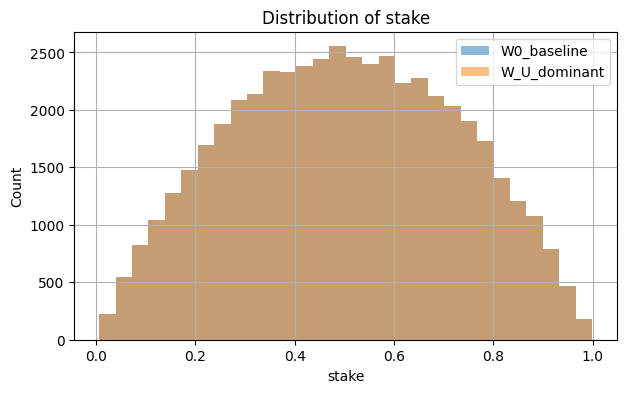

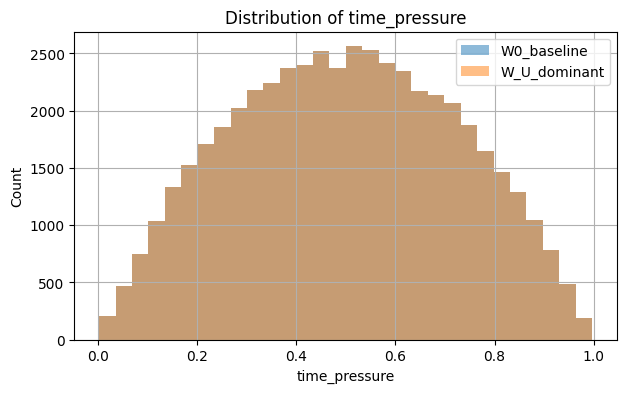

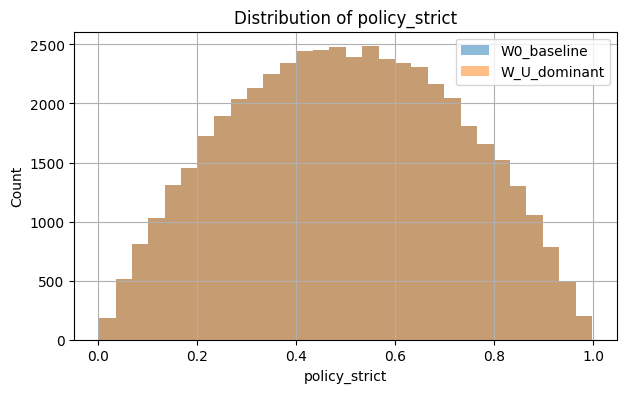

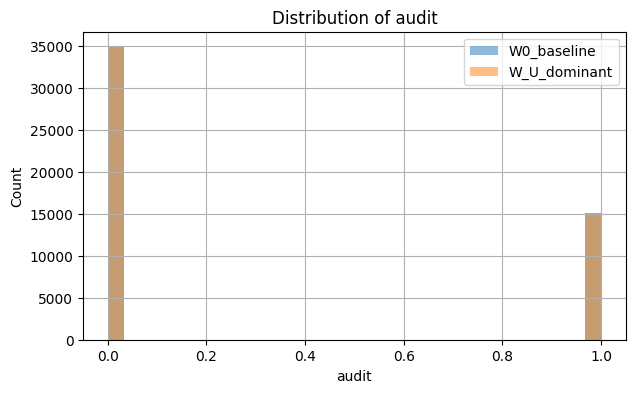

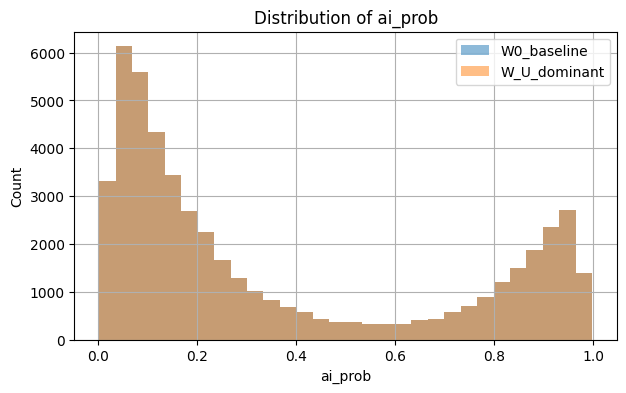

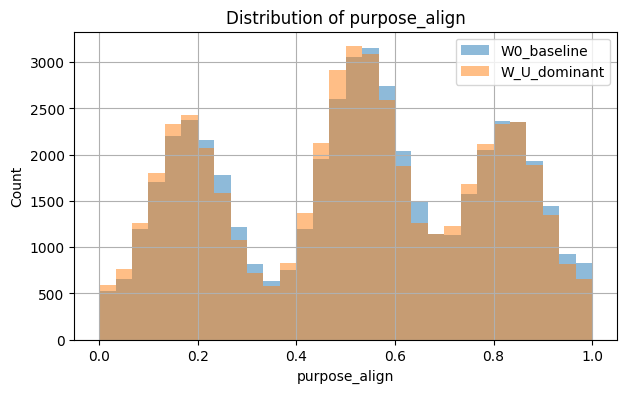

In [29]:
plot_cols = [c for c in KEY_COLS if c != 'override']

for col in plot_cols:
    plt.figure(figsize=(7, 4))
    plotted = False
    for name, df in datasets.items():
        if col in df.columns:
            df[col].dropna().hist(bins=30, alpha=0.5, label=name)
            plotted = True
    if plotted:
        plt.title(f'Distribution of {col}')
        plt.xlabel(col)
        plt.ylabel('Count')
        plt.legend()
        plt.show()


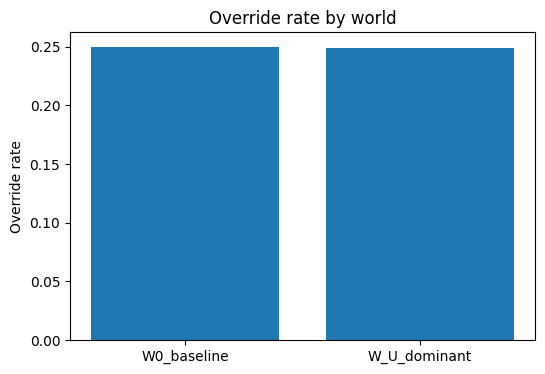

In [30]:
override_rates = {name: df['override'].mean() for name, df in datasets.items() if 'override' in df.columns}

plt.figure(figsize=(6, 4))
plt.bar(list(override_rates.keys()), list(override_rates.values()))
plt.title('Override rate by world')
plt.ylabel('Override rate')
plt.show()
